# 04 · Tract-level aggregates and validation

Sanity checks on the per-tract Overture aggregates: distributions, agreement with independent counts, geometry, completeness, outliers and scaling. Reads the committed `analysis_outputs/` tables.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "analysis_outputs").exists())
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})

REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

# one table: Overture aggregates + ACS + strata, one row per scored tract (built by the earlier notebooks)
df = pd.read_parquet(OUT / "tract_analysis_table.parquet")
df["land_km2"] = df.ALAND / 1e6

def box_by_region(ax, col, data=None, log=False, title="", ylabel=None):
    """Box plot of one column for each region (log10 if log=True), n shown under each box."""
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    """Number of values outside the 1.5 x IQR fences."""
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    """Annotated heatmap of a DataFrame."""
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. Distribution of the per-tract aggregates

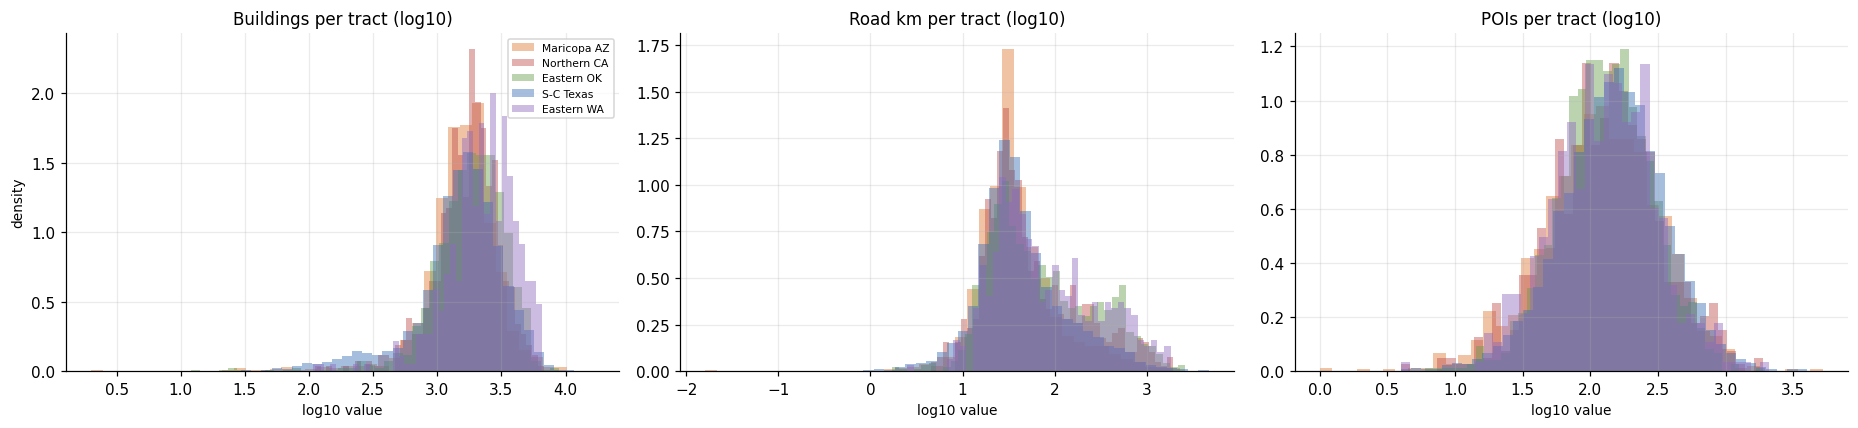

                  bldg_n  road_km_all  poi_n
region                                      
maricopa-az       1646.0         33.3  120.0
northern-ca       1810.0         39.2  134.0
eastern-ok        1939.5         55.2  128.0
south-central-tx  1659.0         36.3  151.0
eastern-wa        2335.0         59.3  129.0


In [2]:
F = {"bldg_n": "Buildings per tract", "road_km_all": "Road km per tract", "poi_n": "POIs per tract"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (c, t) in zip(ax, F.items()):
    for r in REG:
        x = df.loc[df.region == r, c]; a.hist(np.log10(x[x > 0]), bins=40, alpha=.45, density=True, color=COL[r], label=NAME[r])
    a.set_title(t + " (log10)"); a.set_xlabel("log10 value")
ax[0].legend(fontsize=7); ax[0].set_ylabel("density"); plt.tight_layout(); plt.show()
print(df.groupby("region")[list(F)].median().reindex(REG).round(1).to_string())

**Takeaway:** on the log scale each aggregate is roughly bell-shaped and the regions overlap heavily. On the raw scale they have long right tails, so later work uses logs or ratios.

## 2. Do our building counts agree with independent counts?

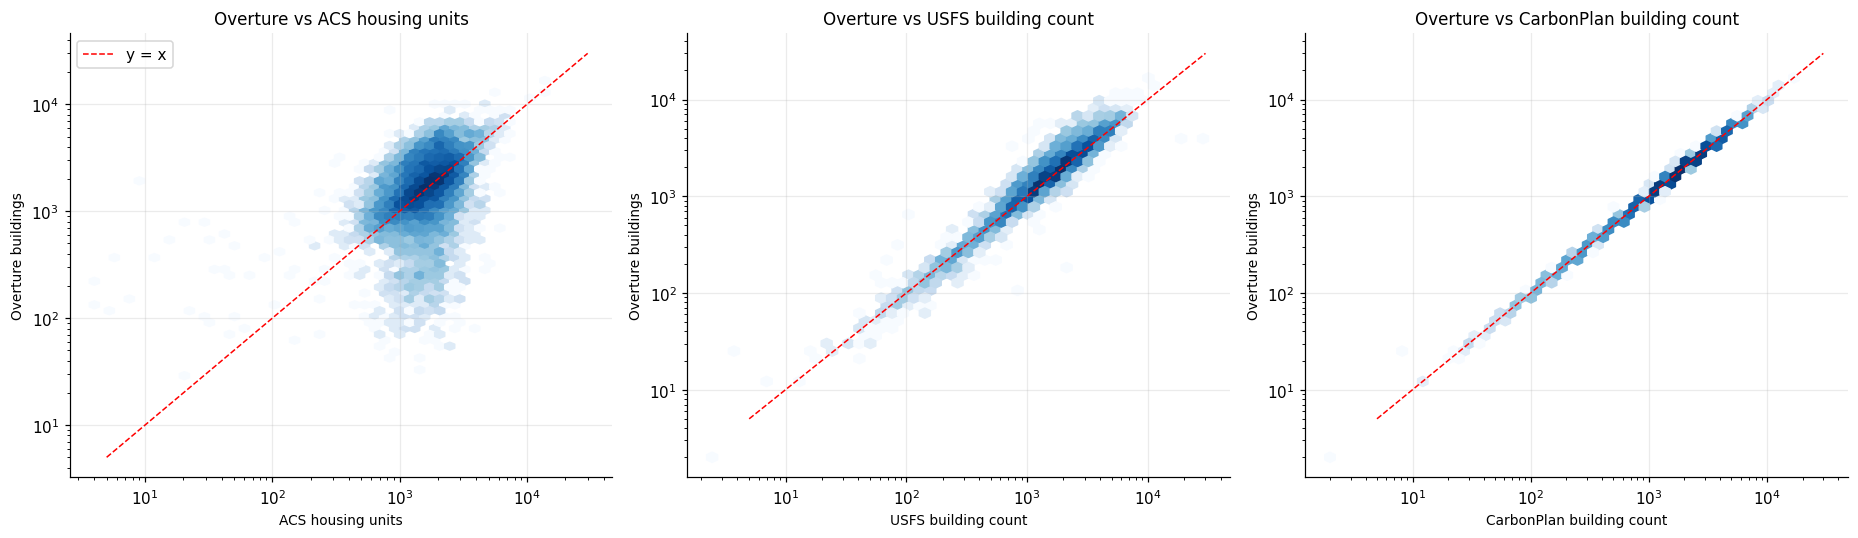

                reference  Spearman  median ratio
        ACS housing units     0.469         1.067
      USFS building count     0.956         1.021
CarbonPlan building count     1.000         0.998


In [3]:
ref = [("housing_units", "ACS housing units"), ("usfs_BuildingCount_sum", "USFS building count"), ("carbonplan_buildings", "CarbonPlan building count")]
fig, ax = plt.subplots(1, 3, figsize=(17, 5)); rows = []
for a, (c, t) in zip(ax, ref):
    d = df[(df[c] > 0) & (df.bldg_n > 0)]
    a.hexbin(d[c], d.bldg_n, gridsize=45, xscale="log", yscale="log", cmap="Blues", mincnt=1, bins="log"); a.plot([5, 3e4], [5, 3e4], "r--", lw=1, label="y = x")
    a.set(xlabel=t, ylabel="Overture buildings", title=f"Overture vs {t}"); rows.append((t, stats.spearmanr(d[c], d.bldg_n)[0], (d.bldg_n / d[c]).median()))
ax[0].legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame(rows, columns=["reference", "Spearman", "median ratio"]).round(3).to_string(index=False))

**Takeaway:** against housing units the cloud is wide (rural tracts sit above the line because of outbuildings, apartment areas below). Against the USFS count it hugs the line. Against CarbonPlan the points lie exactly on the line (Spearman about 1.0, median ratio 0.998), so CarbonPlan is a copy of Overture's own count, not an independent check.

## 3. Geometry check: do our tract areas match the census?

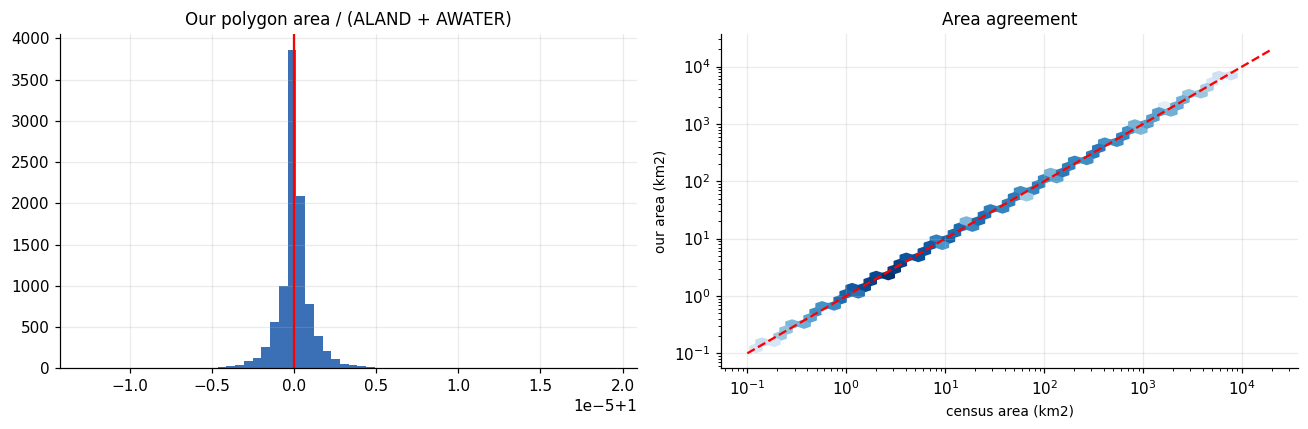

median ratio 1.0000; largest deviation from 1: 0.0000


In [4]:
df["area_ratio"] = df.tract_area_km2 / ((df.ALAND + df.AWATER) / 1e6)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df.area_ratio.clip(.98, 1.02), bins=60, color="#3b6fb6"); ax[0].axvline(1, color="r"); ax[0].set_title("Our polygon area / (ALAND + AWATER)")
ax[1].hexbin((df.ALAND + df.AWATER) / 1e6, df.tract_area_km2, gridsize=40, xscale="log", yscale="log", cmap="Blues", mincnt=1, bins="log"); ax[1].plot([.1, 2e4], [.1, 2e4], "r--"); ax[1].set(xlabel="census area (km2)", ylabel="our area (km2)", title="Area agreement")
plt.tight_layout(); plt.show(); print(f"median ratio {df.area_ratio.median():.4f}; largest deviation from 1: {(df.area_ratio - 1).abs().max():.4f}")

**Takeaway:** the ratio is 1.000 for every tract, so the projection and polygons are consistent with the census and per-km2 densities can be trusted.

## 4. Completeness: how much of each layer lands in a scored tract?

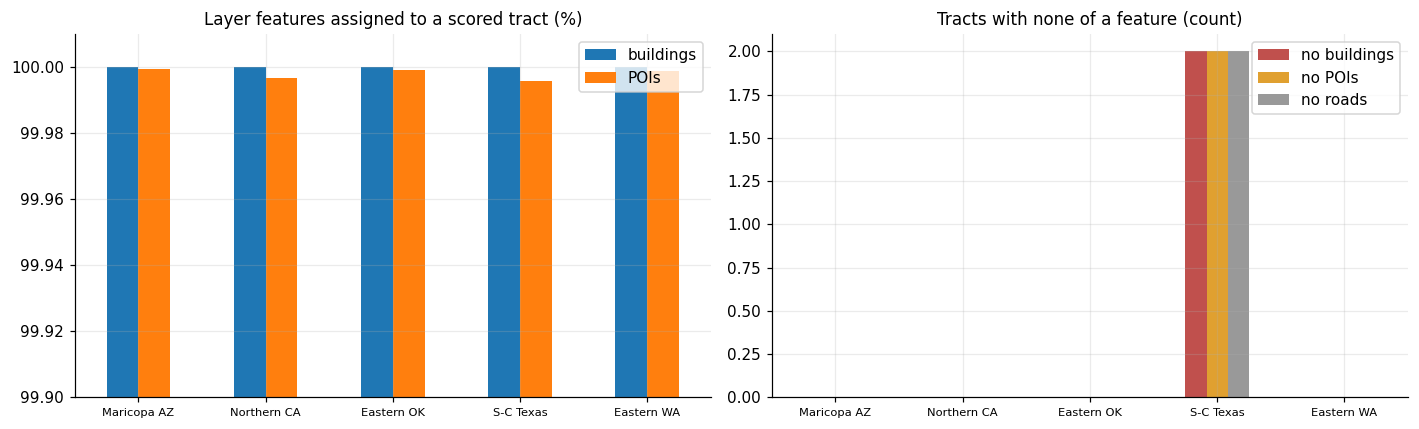

                  buildings     POIs
maricopa-az        100.0000  99.9993
northern-ca        100.0000  99.9966
eastern-ok         100.0000  99.9990
south-central-tx   100.0000  99.9959
eastern-wa          99.9999  99.9987


In [5]:
tot = {"buildings": dict(zip(REG, [2908224, 1164724, 2551694, 11463801, 1081346])), "POIs": dict(zip(REG, [300046, 116897, 207369, 1300334, 76491]))}
got = {"buildings": df.groupby("region").bldg_n.sum(), "POIs": df.groupby("region").poi_n.sum()}
cov = pd.DataFrame({k: {r: got[k][r] / tot[k][r] for r in REG} for k in tot}).reindex(REG)
zero = pd.DataFrame({"no buildings": df.groupby("region").bldg_n.apply(lambda s: (s == 0).sum()), "no POIs": df.groupby("region").poi_n.apply(lambda s: (s == 0).sum()), "no roads": df.groupby("region").road_km_all.apply(lambda s: (s == 0).sum())}).reindex(REG)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(cov * 100).plot.bar(ax=ax[0], rot=0); ax[0].set_ylim(99.9, 100.01); ax[0].set_title("Layer features assigned to a scored tract (%)")
zero.plot.bar(ax=ax[1], rot=0, color=["#c0504d", "#e0a030", "#999"]); ax[1].set_title("Tracts with none of a feature (count)")
for a in ax: a.set_xticklabels([NAME[r] for r in REG], fontsize=7.5); a.set_xlabel("")
plt.tight_layout(); plt.show(); print((cov * 100).round(4).to_string())

**Takeaway:** over 99.99% of buildings and POIs fall inside a scored tract, so the spatial join loses almost nothing. The only empty tracts are the two all-water Texas tracts.

## 5. Outliers and heavy tails

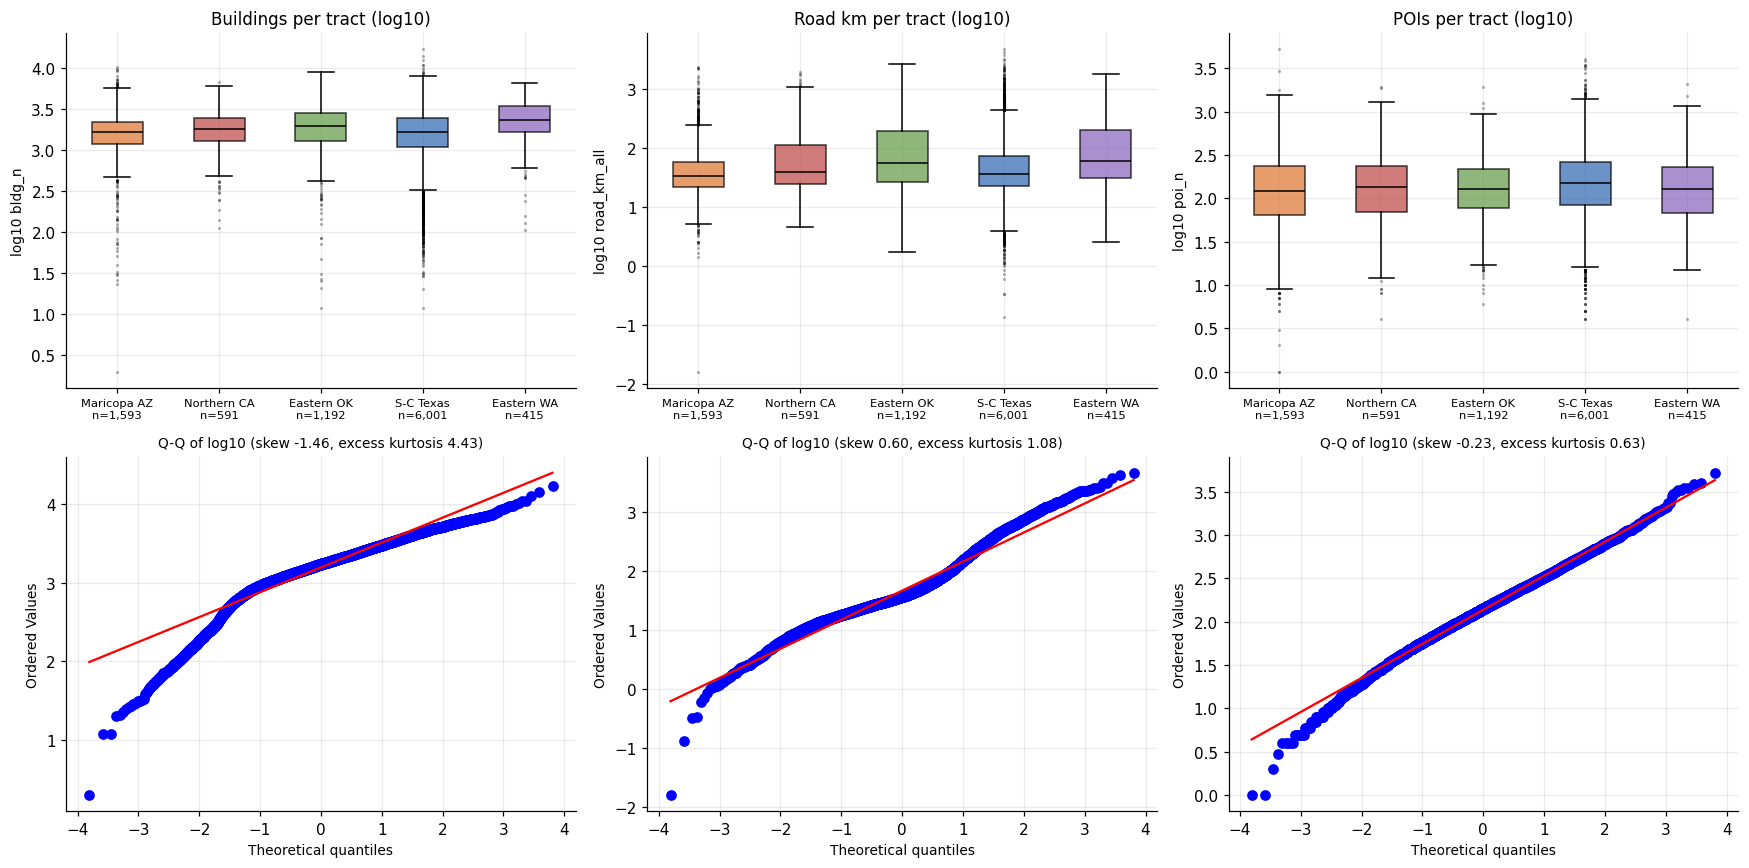

              raw  log10
bldg_n        413    498
road_km_all  1395    471
poi_n         663    137


In [6]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for j, (c, t) in enumerate(F.items()):
    box_by_region(ax[0, j], c, log=True, title=t + " (log10)"); x = np.log10(df[c][df[c] > 0])
    stats.probplot(x, plot=ax[1, j]); ax[1, j].set_title(f"Q-Q of log10 (skew {stats.skew(x):.2f}, excess kurtosis {stats.kurtosis(x):.2f})", fontsize=9)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"raw": {k: n_outliers(df[k]) for k in F}, "log10": {k: n_outliers(np.log10(df[k][df[k] > 0])) for k in F}}).to_string())

**Takeaway:** the log transform cuts IQR outliers sharply for road km (1,395 to 471) and POIs (663 to 137) but not for buildings (413 to 498, the low tail is now flagged). The remaining outliers are real (huge rural tracts, dense urban cores) and should be kept.

## 6. How do the aggregates scale with tract size?

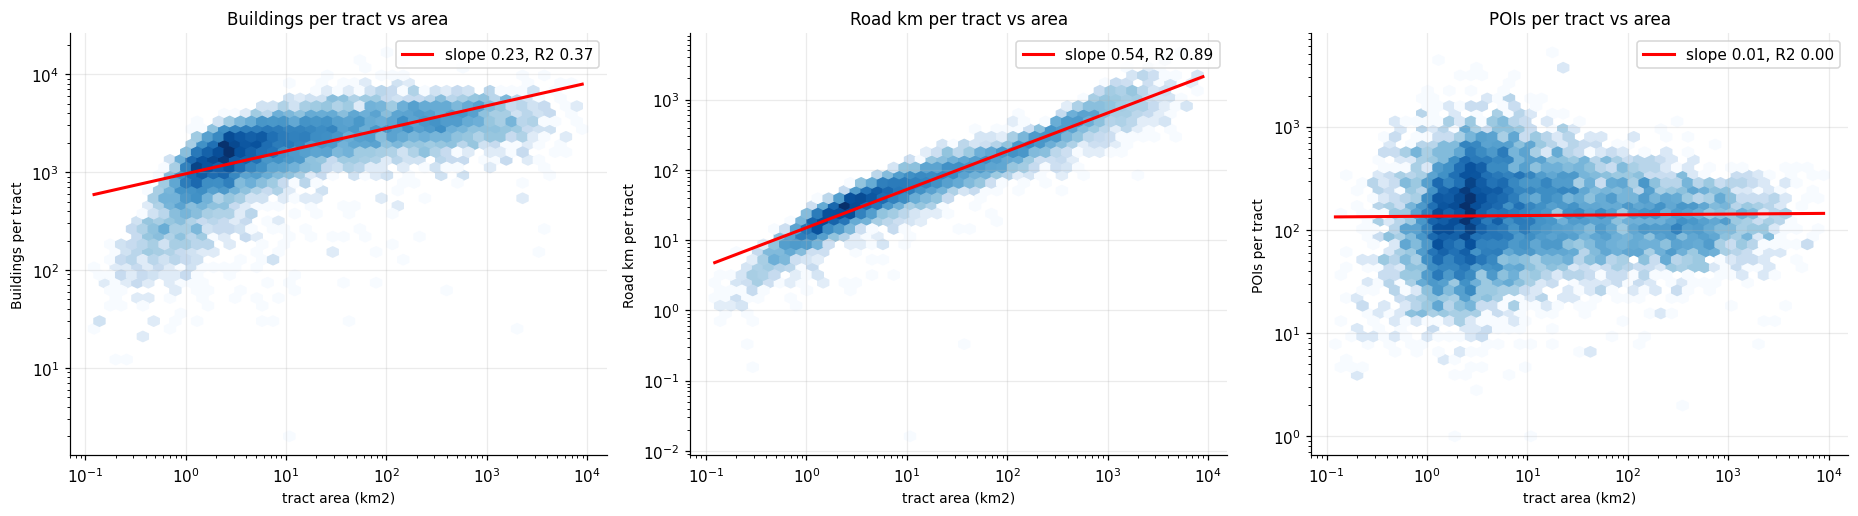

          aggregate  elasticity   R2
Buildings per tract        0.23 0.37
  Road km per tract        0.54 0.89
     POIs per tract        0.01 0.00


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8)); rows = []
for a, (c, t) in zip(ax, F.items()):
    d = df[(df[c] > 0) & (df.tract_area_km2 > 0)]; lx, ly = np.log10(d.tract_area_km2), np.log10(d[c]); sl, ic, rr, p, se = stats.linregress(lx, ly)
    a.hexbin(d.tract_area_km2, d[c], gridsize=45, xscale="log", yscale="log", cmap="Blues", mincnt=1, bins="log"); xs = np.linspace(lx.min(), lx.max(), 50)
    a.plot(10 ** xs, 10 ** (ic + sl * xs), "r", lw=2, label=f"slope {sl:.2f}, R2 {rr ** 2:.2f}"); a.set(xlabel="tract area (km2)", ylabel=t, title=f"{t} vs area"); a.legend(); rows.append((t, sl, rr ** 2))
plt.tight_layout(); plt.show(); print(pd.DataFrame(rows, columns=["aggregate", "elasticity", "R2"]).round(2).to_string(index=False))

**Takeaway:** road length grows with area (elasticity 0.54, R2 0.89), buildings only weakly (0.23, R2 0.37), and POI counts not at all (slope 0.01). Big tracts are rural and sparse, so POIs follow people, not land. Raw counts must never be compared across tracts of very different size.